In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import pylab as pl
import numpy as np
%matplotlib inline

In [3]:
import os
import shutil
import pandas as pd

# Define paths
SOURCE_PATH = r"C:\Users\mehdi\Documents\ML-GitHub-Projects\simple-linear-regression\data\Salary_data.csv"
DATASET_NAME = "Salary_data.csv"

# Check and manage dataset file
if not os.path.exists(DATASET_NAME):
    if os.path.exists(SOURCE_PATH):
        print("Copying dataset to project directory...")
        shutil.copy(SOURCE_PATH, DATASET_NAME)
        print("Dataset successfully copied! ✅")
    else:
        print("❌ Error: Dataset file not found at the source path.")
else:
    print("Dataset already exists in project directory. Ready to use! ✅")

# Load dataset into DataFrame
if os.path.exists(DATASET_NAME):
    df = pd.read_csv(DATASET_NAME)
    print("Data loaded successfully! 📊")
    print(df.head())

Copying dataset to project directory...
Dataset successfully copied! ✅
Data loaded successfully! 📊
   YearsExperience  Salary
0              1.1   39343
1              1.3   46205
2              1.5   37731
3              2.0   43525
4              2.2   39891


In [5]:
df = pd.read_csv("Salary_data.csv")
df.head()

,YearsExperience,Salary
0,1.1,39343
1,1.3,46205
2,1.5,37731
3,2.0,43525
4,2.2,39891


In [6]:
df = pd.read_csv("Salary_data.csv")
df.tail()

,YearsExperience,Salary
30,11.2,127345
31,11.5,126756
32,12.3,128765
33,12.9,135675
34,13.5,139465


In [7]:
df.describe()

,YearsExperience,Salary
count,35.000000,35.000000
mean,6.308571,83945.600000
std,3.618610,32162.673003
min,1.100000,37731.000000
25%,3.450000,57019.000000
50%,5.300000,81363.000000
75%,9.250000,113223.500000
max,13.500000,139465.000000


In [13]:
cdf = df [['YearsExperience','Salary']]
cdf.head(7)

,YearsExperience,Salary
0,1.1,39343
1,1.3,46205
2,1.5,37731
3,2.0,43525
4,2.2,39891
5,2.9,56642
6,3.0,60150


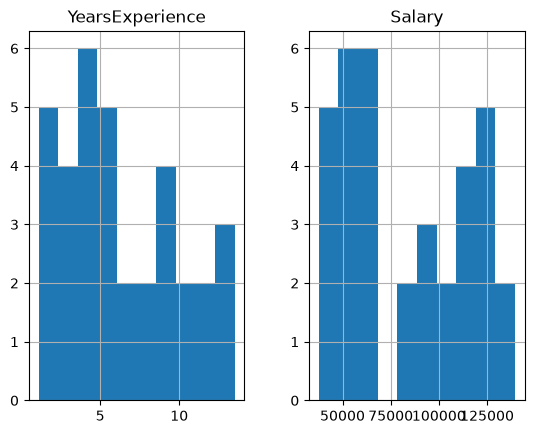

In [14]:
viz = cdf[['YearsExperience','Salary']]
viz.hist()
plt.show()

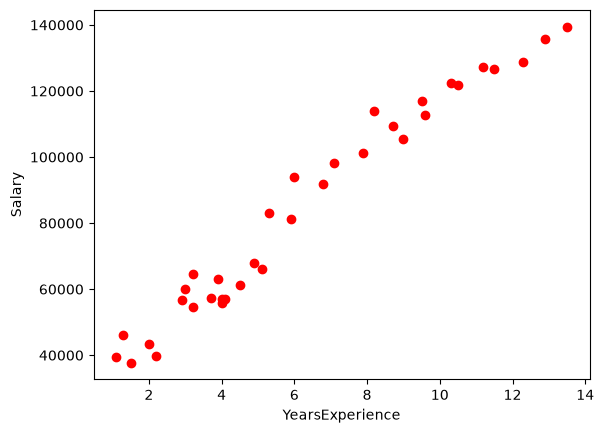

In [17]:
plt.scatter(cdf.YearsExperience , cdf.Salary , color = "r")
plt.xlabel("YearsExperience")
plt.ylabel("Salary")
plt.show()

In [20]:
msk = np.random.rand(len(df)) < 0.8
train = cdf[msk]
test = cdf[~msk]

print(f"Train set count: {len(train)}")
print(f"Test set count: {len(test)}")

Train set count: 27
Test set count: 8


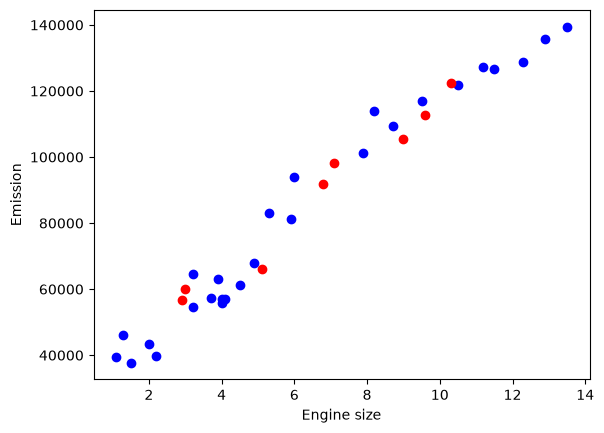

In [21]:
fig = plt.figure()
ax1 = fig.add_subplot(111)
ax1.scatter(train.YearsExperience, train.Salary,  color='blue')
ax1.scatter(test.YearsExperience, test.Salary,  color='red')
plt.xlabel("Engine size")
plt.ylabel("Emission")
plt.show()

In [25]:
from sklearn import linear_model
regr = linear_model.LinearRegression()
train_x = np.asanyarray(train[['YearsExperience']])
train_y = np.asanyarray(train[['Salary']])
regr.fit (train_x, train_y)
# The coefficients
print ('Coefficients: ', regr.coef_)
print ('Intercept: ',regr.intercept_)

Coefficients:  [[8726.81570648]]
Intercept:  [28417.69544511]


Text(0, 0.5, 'Emission')

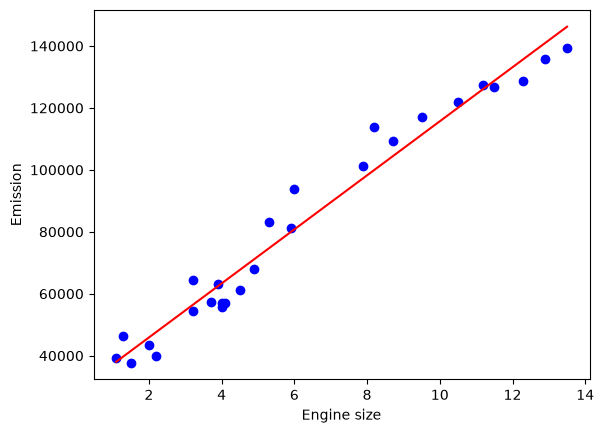

In [26]:
plt.scatter(train.YearsExperience, train.Salary,  color='blue')
plt.plot(train_x, regr.coef_[0][0]*train_x + regr.intercept_[0], '-r')
plt.xlabel("Engine size")
plt.ylabel("Emission")

In [27]:
from sklearn.metrics import r2_score

test_x = np.asanyarray(test[['YearsExperience']])
test_y = np.asanyarray(test[['Salary']])
test_y_ = regr.predict(test_x)

print("Mean absolute error: %.2f" % np.mean(np.absolute(test_y_ - test_y)))
print("Residual sum of squares (MSE): %.2f" % np.mean((test_y_ - test_y) ** 2))
print("R2-score: %.2f" % r2_score(test_y , test_y_) )

Mean absolute error: 4142.59
Residual sum of squares (MSE): 22978069.52
R2-score: 0.96
